# One-Galaxy Kinematic Lensing Inference

**Showcase notebook.** This is the main end-to-end demonstration of KINO: starting
from a single intrinsic disc galaxy, we apply a *known* shear, simulate what an
IFU would observe, and then run nested-sampling inference to recover that shear
back out of the mock data. Because the input shear is known, this is an
injection-recovery test -- the simplest possible check that the whole pipeline
(forward model + instrument + inference) is self-consistent.

Pipeline:

```
intrinsic disc (image + Vlos) -> apply shear (g1, g2) -> IFU backend -> mock datacube
                                                                              |
                     moment maps -> nautilus posterior on (g1, g2, ...)  <---+
```

This rewrites the earlier scaffold version of this notebook against the real
Phase 1-3/5 API (`README.md`'s roadmap) rather than the aspirational one it
started from. Two things to flag up front, both explained in `CLAUDE.md`:

- **Only the IFU backend has a shear likelihood.** A `SlitSpectrograph` mock
  is shown below (Sec. 6) since the forward model supports it, but there is
  no `kino.inference` likelihood for it yet -- inference here is IFU-only.
- **Real degeneracies are on display, not hidden.** Inclination-velocity and
  shear-ellipticity degeneracies are real (`CLAUDE.md`, "Things to be careful
  about"); the fit below leaves `inc` and `v_flat` free specifically so the
  resulting shear posterior is honest about how much those degeneracies
  widen it, rather than an artificially tight result from fixing everything
  else at the truth.

## 0. Setup

In [1]:
import dataclasses

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np

import kino
from kino.analysis.moments import compute_moment_maps
from kino.galaxy import DiscGalaxy
from kino.inference import IFUMomentLikelihood, build_prior, fit_shear, tully_fisher_prior
from kino.instruments.ifu import IFU
from kino.instruments.slit import SlitSpectrograph
from kino.lensing import apply_shear

rng = np.random.default_rng(seed=0)  # explicit, seeded RNG -- see CLAUDE.md conventions
print(f"kino {kino.__version__}")

kino 0.1.0.dev0


## 1. Intrinsic disc galaxy

Define the unlensed galaxy: disc geometry (inclination, position angle,
effective radius, rotation curve, systemic velocity, intrinsic dispersion).
Positions in arcsec, velocities in km/s, angles in degrees -- see `CLAUDE.md`
for the full unit and sign conventions. `flux` is in `DiscGalaxy`'s own
arbitrary units (the "Instrument flux calibration" convention); the physical
line flux is supplied separately at `observe()` time, in Sec. 4.

In [2]:
gal = DiscGalaxy(
    r_e=0.3,  # Sersic effective radius, arcsec
    inc=55.0,  # inclination, degrees (0 = face-on, 90 = edge-on)
    pa=30.0,  # position angle, degrees East of North
    v_flat=180.0,  # asymptotic rotation velocity, km/s
    z=0.68,  # redshift (redshifts Halpha to ~1.10 um, GMTIFS's H-band setting)
    sigma0=20.0,  # intrinsic velocity dispersion at r=0, km/s
    flux=1.0,  # arbitrary units -- see kino's flux-calibration convention
)
gal

DiscGalaxy(r_e=0.3, inc=55.0, pa=30.0, v_flat=180.0, z=0.68, sersic_n=1.0, flux=1.0, rotation_curve='arctan', r_t=0.3, x0=0.0, y0=0.0, v_sys=0.0, sigma0=20.0, sigma_grad=0.0)

## 2. Apply a known shear

This is the ground truth for the injection-recovery test below: we shear the
disc by a chosen `(g1, g2)` and later check that inference recovers it. The
shear is applied jointly to the surface brightness **and** the velocity
field via `LensedScene` -- shearing only the morphology is a classic bug
(see `CLAUDE.md`, "Things to be careful about").

In [3]:
g1_true, g2_true = 0.035, -0.02
scene = apply_shear(gal, g1_true, g2_true)
scene

LensedScene(galaxy=DiscGalaxy(r_e=0.3, inc=55.0, pa=30.0, v_flat=180.0, z=0.68, sersic_n=1.0, flux=1.0, rotation_curve='arctan', r_t=0.3, x0=0.0, y0=0.0, v_sys=0.0, sigma0=20.0, sigma_grad=0.0), g1=0.035, g2=-0.02)

## 3. Choose an instrument: IFU

Instrument behaviour (PSF, LSF, spatial/spectral sampling, throughput,
noise) lives entirely behind `Instrument.observe(scene)` and a YAML config
-- never in the galaxy or lensing code. `kino/config/gmtifs.yaml` is a
GMTIFS-like fiducial NIR AO-IFU config (`IFU.from_config`).

For this notebook we shrink the field of view, spectral sampling, and
spectral *window* relative to the fiducial config, via `dataclasses.replace`
(everything else -- PSF, LSF resolving power, throughput, detector, sky --
stays as configured):

- **Field of view / spectral channels down**, purely so nested sampling
  below (which calls `IFU.observe` thousands of times) finishes in a
  notebook-friendly amount of time -- not a physical limitation.
- **Spectral window narrowed to ~800 km/s around the redshifted line**,
  which *is* physically motivated: `kino.analysis.moments`' docstring (and
  `notebooks/07_moment_window_width_caveat.ipynb`) show that a window much
  wider than the line makes the `dispersion` moment noise-dominated.
  `gmtifs.yaml`'s own native window (1.10-1.14 um, chosen to just cover
  GMTIFS's full science range) is wider than that here -- so we narrow it
  rather than rely on `crop_to_line` after the fact, since
  `IFUMomentLikelihood` always renders the model through *this* `IFU`'s own
  native window on every likelihood call (see its module docstring).

In [4]:
ifu_full = IFU.from_config("../kino/config/gmtifs.yaml")

line_wavelength = 0.65628 * u.um  # rest-frame Halpha
band_center = (line_wavelength * (1.0 + gal.z)).to(u.um)
half_width = (band_center * 400.0 / 3.0e5).to(u.um)  # +/- 400 km/s

ifu = dataclasses.replace(
    ifu_full,
    nx=24,
    ny=24,
    n_wave=25,
    wavelength_min=band_center - half_width,
    wavelength_max=band_center + half_width,
)
window = (ifu.wavelength_min, ifu.wavelength_max)
print(f"observed line centre: {band_center:.5f}")
print(f"window: [{window[0]:.5f}, {window[1]:.5f}]")
ifu

observed line centre: 1.10255 um
window: [1.10108 um, 1.10402 um]


IFU(pixel_scale=<Quantity 0.05 arcsec>, nx=24, ny=24, wavelength_min=<Quantity 1.10108033 um>, wavelength_max=<Quantity 1.10402047 um>, n_wave=25, psf=PSF(seeing_fwhm=<Quantity 0.05 arcsec>, defocus=0.0, astig1=0.0, astig2=0.0, coma1=0.0, coma2=0.0, trefoil1=0.0, trefoil2=0.0, spher=0.0), lsf=LSF(resolving_power=8000, fwhm=None), throughput=Throughput(wavelength=<Quantity [1.1 , 1.11, 1.12, 1.13, 1.14] um>, transmission=array([0.3 , 0.35, 0.35, 0.35, 0.3 ])), aperture_diameter=<Quantity 24.5 m>, detector=Detector(read_noise=<Quantity 5. electron>, dark_current=<Quantity 0.01 electron / s>), exposure_time=<Quantity 600. s>, obstruction_fraction=0.0, n_exposures=6, sky_electron_rate=<Quantity 3. electron / s>)

## 4. Simulate: IFU mock observation

`IFU.observe` renders `scene`'s emission line into a `Datacube` of detected
electrons (`rng=None` for the noiseless expected-count cube, or a seeded
generator for one noisy realisation). Physical flux calibration is supplied
here, not on `DiscGalaxy` -- see Sec. 1.

In [5]:
line_flux = 5e-16 * u.erg / u.s / u.cm**2  # intrinsic (unlensed) line flux

cube_noiseless = ifu.observe(scene, line_flux=line_flux, line_wavelength=line_wavelength, rng=None)
data = ifu.observe(scene, line_flux=line_flux, line_wavelength=line_wavelength, rng=rng)

print(f"cube shape (n_wave, ny, nx): {data.flux.shape}")
print(f"noiseless peak counts: {cube_noiseless.flux.max():.0f} electron")
print(f"noisy realisation range: [{data.flux.min():.0f}, {data.flux.max():.0f}] electron")

cube shape (n_wave, ny, nx): (25, 24, 24)
noiseless peak counts: 20490 electron
noisy realisation range: [10421, 20595] electron


## 5. Reduce to moment maps

`kino.analysis.moments.compute_moment_maps` turns any `Datacube` into
flux/Vlos/dispersion moment maps, with delta-method error propagation from
the cube's `variance` and an S/N mask. `check_window=True` (the default)
would warn if the spectral window above were too wide relative to the line
-- it doesn't, confirming Sec. 3's choice.

In [6]:
moments = compute_moment_maps(data, line_wavelength=line_wavelength, snr_threshold=3.0)

n_spaxels = data.flux.shape[1] * data.flux.shape[2]
n_valid = int(np.sum(~np.isnan(moments.vlos)))
print(f"{n_valid} / {n_spaxels} spaxels pass snr_threshold=3")
v_lo, v_hi = np.nanmin(moments.vlos), np.nanmax(moments.vlos)
d_lo, d_hi = np.nanmin(moments.dispersion), np.nanmax(moments.dispersion)
print(f"vlos range: [{v_lo:.0f}, {v_hi:.0f}] km/s")
print(f"dispersion range: [{d_lo:.0f}, {d_hi:.0f}] km/s")

182 / 576 spaxels pass snr_threshold=3
vlos range: [-219, 226] km/s
dispersion range: [0, 193] km/s


## 6. Visualize the mock data

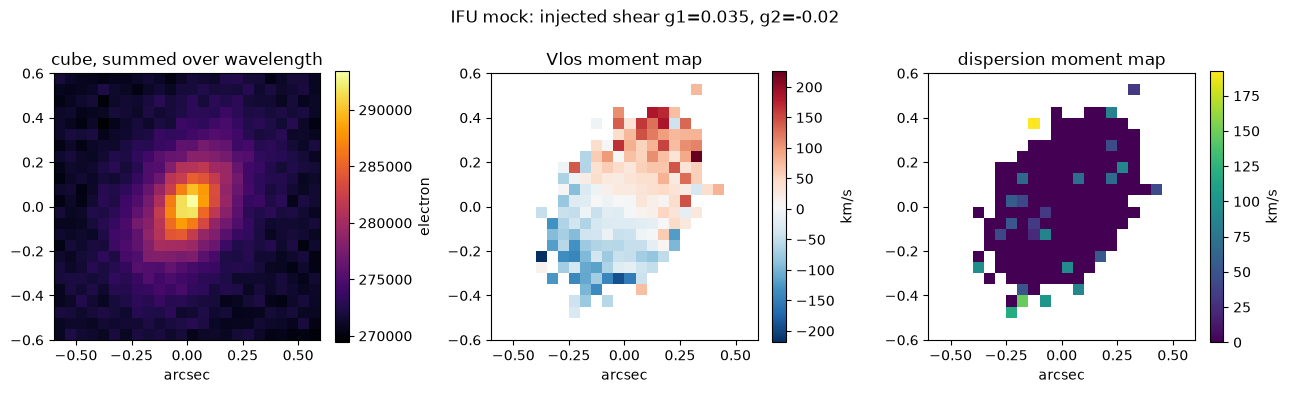

In [7]:
fov = (ifu.nx * ifu.pixel_scale).to_value(u.arcsec)
extent = [-fov / 2, fov / 2, -fov / 2, fov / 2]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

im0 = axes[0].imshow(data.flux.sum(axis=0), origin="lower", cmap="inferno", extent=extent)
axes[0].set_title("cube, summed over wavelength")
axes[0].set_xlabel("arcsec")
fig.colorbar(im0, ax=axes[0], label="electron", fraction=0.046)

im1 = axes[1].imshow(moments.vlos, origin="lower", cmap="RdBu_r", extent=extent)
axes[1].set_title("Vlos moment map")
axes[1].set_xlabel("arcsec")
fig.colorbar(im1, ax=axes[1], label="km/s", fraction=0.046)

im2 = axes[2].imshow(moments.dispersion, origin="lower", cmap="viridis", extent=extent)
axes[2].set_title("dispersion moment map")
axes[2].set_xlabel("arcsec")
fig.colorbar(im2, ax=axes[2], label="km/s", fraction=0.046)

fig.suptitle(f"IFU mock: injected shear g1={g1_true}, g2={g2_true}")
fig.tight_layout()

## 7. Aside: the slit/grism backend

The same forward model also drives `kino.instruments.slit.SlitSpectrograph`
(a companion broadband image + a dispersed 2-D spectrum, with slit losses
and misalignment falling directly out of the rendering -- see `CLAUDE.md`).
**No shear likelihood exists for it yet** (`kino.inference` is IFU-only), so
this is a forward-model demo only, on a separate galaxy/line chosen to sit
inside GMACS's fiducial optical window (`kino/config/gmacs.yaml`, 0.50-0.52
um) -- not a continuation of the inference below.

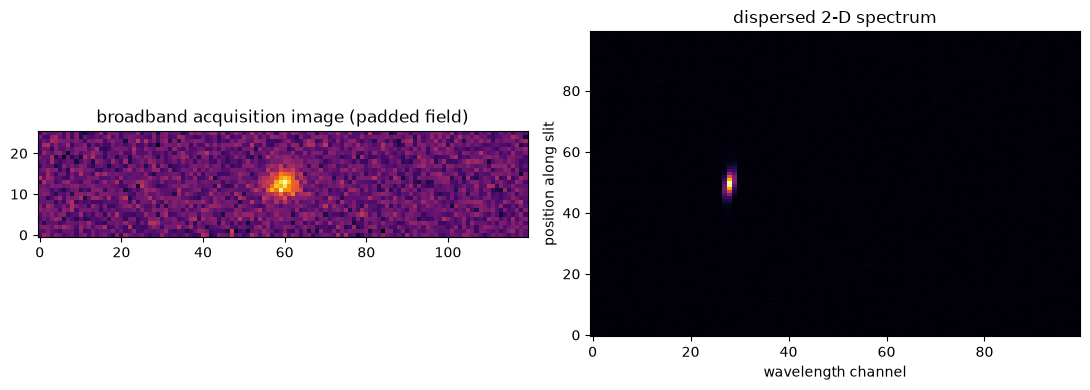

In [8]:
# same geometry, a redshift GMACS's window can actually reach
gal_slit = dataclasses.replace(gal, z=0.01)
scene_slit = apply_shear(gal_slit, g1_true, g2_true)

slit = SlitSpectrograph.from_config("../kino/config/gmacs.yaml")
line_wavelength_oiii = 0.5007 * u.um  # rest-frame [OIII] 5007

slit_obs = slit.observe(
    scene_slit, line_flux=line_flux, line_wavelength=line_wavelength_oiii, rng=rng
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(slit_obs.image, origin="lower", cmap="inferno")
axes[0].set_title("broadband acquisition image (padded field)")
axes[1].imshow(slit_obs.spectrum.flux[:, :, 0].T, origin="lower", aspect="auto", cmap="inferno")
axes[1].set_xlabel("wavelength channel")
axes[1].set_ylabel("position along slit")
axes[1].set_title("dispersed 2-D spectrum")
fig.tight_layout()

## 8. Set up the shear inference

`IFUMomentLikelihood` compares flux/Vlos/dispersion moment maps, not raw
cube pixels: every trial `(g1, g2, ...)` is forward-modelled through the
*same*, fixed `ifu` used for the data, so PSF-driven beam smearing cancels
between model and data rather than biasing the fit (see the module
docstring and `CLAUDE.md`'s "IFU shear likelihood" convention).

We hold `r_e`, `pa`, `z`, `sigma0`, `flux` and `line_flux` fixed at their
true values (as if known from imaging/redshift/flux-calibration priors) and
leave `g1`, `g2`, `inc`, `v_flat` free -- deliberately including the
inclination-velocity degeneracy in the fit rather than fixing it away.
`v_flat`'s prior is `tully_fisher_prior`, an explicitly **toy, uncalibrated**
Tully-Fisher relation (`CLAUDE.md`) -- its role here is only to keep the
prior volume physically reasonable, not to inject real astrophysical
information.

In [9]:
fixed_galaxy_params = {
    "r_e": gal.r_e,
    "pa": gal.pa,
    "z": gal.z,
    "sigma0": gal.sigma0,
    "flux": gal.flux,
}

likelihood = IFUMomentLikelihood(
    ifu=ifu,
    line_wavelength=line_wavelength,
    data=data,
    fixed_galaxy_params=fixed_galaxy_params,
    fixed_line_flux=line_flux,
)

# sanity check: the log-likelihood at the injected truth should be near its best-fit value
ll_truth = likelihood({"inc": gal.inc, "v_flat": gal.v_flat, "g1": g1_true, "g2": g2_true})
ll_off = likelihood({"inc": gal.inc, "v_flat": gal.v_flat, "g1": g1_true + 0.05, "g2": g2_true})
print(f"log-likelihood at the truth:      {ll_truth:.2f}")
print(f"log-likelihood 0.05 off in g1:    {ll_off:.2f}  (should be lower)")

prior = build_prior(
    {
        "g1": (-0.15, 0.15),
        "g2": (-0.15, 0.15),
        "inc": (30.0, 80.0),
        "v_flat": tully_fisher_prior(gal.flux, v0=180.0, flux0=1.0, scatter_dex=0.15),
    }
)
print(f"free parameters: {prior.dimensionality()}")

log-likelihood at the truth:      -35.35
log-likelihood 0.05 off in g1:    -35.91  (should be lower)
free parameters: 4


## 9. Run inference: recover the posterior

`kino.inference.sampler.fit_shear` is a thin wrapper around **nautilus**
(neural-network-boosted importance nested sampling). `n_live`/`n_eff` are
kept modest here for a notebook-friendly runtime (order a minute); raise
them for a publication-grade posterior.

In [10]:
posterior = fit_shear(prior, likelihood, n_live=150, seed=0, n_eff=300, verbose=False)
posterior

Posterior(log_z=-32.183, n_samples=330)
  g1 = -0.02783  (-0.0854 / +0.11)
  g2 = 0.006735  (-0.1 / +0.0908)
  inc = 52.99  (-16.2 / +17.9)
  v_flat = 144.9  (-23.1 / +39)

## 10. Injection-recovery check

Compare the recovered posterior to the injected truth from Sec. 2/1 -- the
core validation of the whole pipeline. The shear posterior is noticeably
wider than a fit with `inc`/`v_flat` fixed at the truth would give (compare
`tests/inference/test_sampler.py`'s 2-parameter version): that's the
inclination-velocity and shear-ellipticity degeneracies mentioned in Sec. 0
showing up honestly, not a bug.

In [11]:
summary = posterior.summary()
truth = {"g1": g1_true, "g2": g2_true, "inc": gal.inc, "v_flat": gal.v_flat}

for name in posterior.param_names:
    med, minus, plus = summary[name]
    t = truth[name]
    ok = (med - minus) <= t <= (med + plus)
    within = "within 1 sigma" if ok else "OUTSIDE 1 sigma"
    print(
        f"{name:>8s}: truth={t:>8.3f}  recovered={med:>8.3f} (-{minus:.3f}/+{plus:.3f})  [{within}]"
    )

      g1: truth=   0.035  recovered=  -0.028 (-0.085/+0.110)  [within 1 sigma]
      g2: truth=  -0.020  recovered=   0.007 (-0.100/+0.091)  [within 1 sigma]
     inc: truth=  55.000  recovered=  52.987 (-16.172/+17.871)  [within 1 sigma]
  v_flat: truth= 180.000  recovered= 144.916 (-23.120/+38.966)  [within 1 sigma]


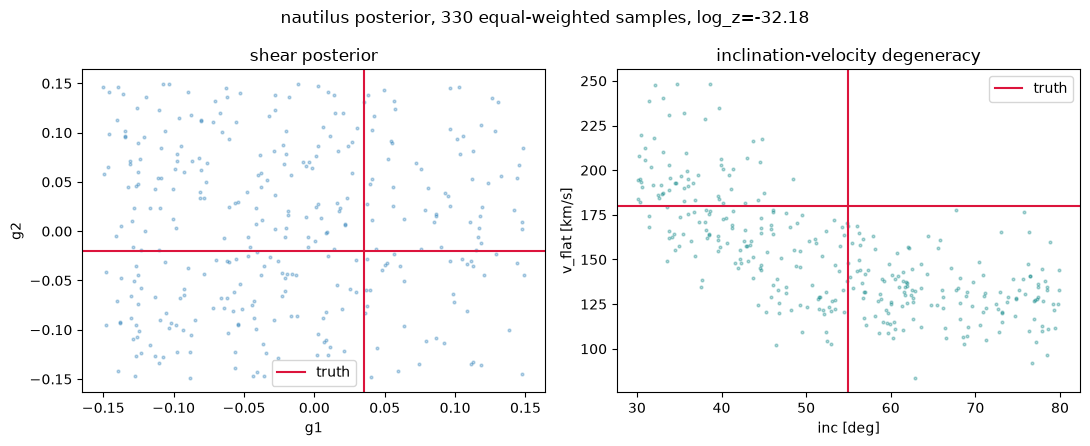

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(posterior.samples["g1"], posterior.samples["g2"], s=4, alpha=0.3)
axes[0].axvline(g1_true, color="crimson", lw=1.5, label="truth")
axes[0].axhline(g2_true, color="crimson", lw=1.5)
axes[0].set_xlabel("g1")
axes[0].set_ylabel("g2")
axes[0].set_title("shear posterior")
axes[0].legend()

axes[1].scatter(posterior.samples["inc"], posterior.samples["v_flat"], s=4, alpha=0.3, color="teal")
axes[1].axvline(gal.inc, color="crimson", lw=1.5, label="truth")
axes[1].axhline(gal.v_flat, color="crimson", lw=1.5)
axes[1].set_xlabel("inc [deg]")
axes[1].set_ylabel("v_flat [km/s]")
axes[1].set_title("inclination-velocity degeneracy")
axes[1].legend()

title = (
    f"nautilus posterior, {posterior.n_samples} equal-weighted samples, log_z={posterior.log_z:.2f}"
)
fig.suptitle(title)
fig.tight_layout()

## Next steps

- **Slit/grism likelihood** (`kino.inference`, Phase 5): build the
  slit-analogue of `IFUMomentLikelihood` (e.g. against the dispersed
  spectrum's own moments) so Sec. 7's mock can feed an inference run too.
- **Phase 4 (`kino.mocks`)**: assemble this notebook's steps into a single
  reproducible, config-driven pipeline (`examples/simulate_one_galaxy.py`,
  `examples/run_inference.py` in the roadmap) rather than a hand-assembled
  notebook.
- **Ensembles and (m, c) bias** (`kino.analysis`): repeat this
  injection-recovery test over many galaxies at fixed shear to characterise
  residual shape noise and multiplicative/additive bias in the recovered
  shear -- the actual scientific deliverable behind KINO's method paper.